# Jupyter-Notebooks: Verwendung und Beispiel

Jupyter ist eine interaktive Arbeitsumgebung für Python. Ein Notebook besteht aus Zellen: In Markdown-Zellen stehen Erklärungen, in Codezellen läuft Python. So lassen sich Programmcode, Ergebnisse und Dokumentation an einem Ort kombinieren.

Jupyter eignet sich zum Lernen, für Datenanalyse und Visualisierungen sowie zum schnellen Testen von Ideen. Der Kernel führt den Code aus und behält Variablen im Arbeitsspeicher. Starte die Zellen am besten von oben nach unten mit `Shift+Enter`; nach einem Kernel-Neustart müssen Variablen durch erneutes Ausführen wieder erstellt werden.

Das folgende Mini-Beispiel zeigt eine direkte Berechnung. Anschließend erstellen und analysieren wir eine CSV-Datei, damit du einen typischen Anwendungsfall siehst.

In [1]:
werte = [12, 18, 15]
durchschnitt = sum(werte) / len(werte)
print(f"Durchschnitt: {durchschnitt}")

Durchschnitt: 15.0


Die Codezelle berechnet den Mittelwert der drei Zahlen. Jupyter zeigt die Ausgabe direkt unter der Zelle; ändere zum Beispiel einen Wert und führe die Zelle erneut aus, um das Ergebnis zu aktualisieren.

## 1. Bibliotheken importieren

`csv` liest und schreibt CSV-Dateien. `os` hilft, den Speicherort im Arbeitsverzeichnis zu bestimmen. Beide Module gehören zur Python-Standardbibliothek und müssen nicht extra installiert werden.

In [2]:
import csv
import os

## 2. Beispieldatei erstellen

Wir schreiben drei Datensätze in `wochenumsatz.csv`. `with open(...)` schließt die Datei nach dem Schreiben automatisch. `newline=""` verhindert bei CSV-Dateien zusätzliche Leerzeilen auf manchen Systemen.

In [3]:
arbeitsverzeichnis = os.getcwd()
dateipfad = os.path.join(arbeitsverzeichnis, "wochenumsatz.csv")

umsatzdaten = [
    {"tag": "Montag", "umsatz_euro": 120.50},
    {"tag": "Dienstag", "umsatz_euro": 95.00},
    {"tag": "Mittwoch", "umsatz_euro": 143.75},
    {"tag": "Donnerstag", "umsatz_euro": 110.25},
    {"tag": "Freitag", "umsatz_euro": 180.00},
]

with open(dateipfad, "w", newline="", encoding="utf-8") as csv_datei:
    felder = ["tag", "umsatz_euro"]
    schreiber = csv.DictWriter(csv_datei, fieldnames=felder)
    schreiber.writeheader()
    schreiber.writerows(umsatzdaten)

print(f"Datei erstellt: {dateipfad}")

Datei erstellt: /workspaces/seminar3/wochenumsatz.csv


## 3. Datei einlesen und verwenden

Die Daten liegen jetzt unabhängig vom Arbeitsspeicher in der CSV-Datei. Mit `csv.DictReader` lesen wir jede Zeile als Wörterbuch ein. Zahlen aus Textdateien müssen wir beim Einlesen selbst in `float` umwandeln.

In [4]:
with open(dateipfad, "r", newline="", encoding="utf-8") as csv_datei:
    leser = csv.DictReader(csv_datei)
    geladene_daten = [
        {"tag": zeile["tag"], "umsatz_euro": float(zeile["umsatz_euro"])}
        for zeile in leser
    ]

for eintrag in geladene_daten:
    print(f"{eintrag['tag']}: {eintrag['umsatz_euro']:.2f} EUR")

Montag: 120.50 EUR
Dienstag: 95.00 EUR
Mittwoch: 143.75 EUR
Donnerstag: 110.25 EUR
Freitag: 180.00 EUR


## 4. Einsatzzweck: Daten auswerten

Die Datei trennt die Daten vom Programmcode. So kann dieselbe Auswertung später erneut mit aktualisierten Daten laufen, und die CSV lässt sich auch in Tabellenprogrammen öffnen. Hier berechnen wir Gesamt- und Durchschnittsumsatz und suchen den umsatzstärksten Tag.

In [5]:
gesamtumsatz = sum(eintrag["umsatz_euro"] for eintrag in geladene_daten)
durchschnitt = gesamtumsatz / len(geladene_daten)
bester_tag = max(geladene_daten, key=lambda eintrag: eintrag["umsatz_euro"])

print(f"Gesamtumsatz: {gesamtumsatz:.2f} EUR")
print(f"Durchschnitt pro Tag: {durchschnitt:.2f} EUR")
print(
    f"Umsatzstärkster Tag: {bester_tag['tag']} "
    f"({bester_tag['umsatz_euro']:.2f} EUR)"
 )

Gesamtumsatz: 649.50 EUR
Durchschnitt pro Tag: 129.90 EUR
Umsatzstärkster Tag: Freitag (180.00 EUR)


### Ausführen und weiterverwenden

Führe die Zellen von oben nach unten aus (`Shift+Enter`). Die späteren Zellen verwenden Variablen aus den vorherigen Zellen. Nach einem Kernel-Neustart sind diese Variablen weg; führe dann alle Zellen erneut in der richtigen Reihenfolge aus. Die CSV-Datei bleibt dagegen im Arbeitsverzeichnis erhalten.

## 5. Daten visuell darstellen

Diagramme helfen, Muster schneller zu erkennen als eine reine Zahlenliste. Balkendiagramme vergleichen Kategorien, Liniendiagramme zeigen Veränderungen über die Zeit, Histogramme zeigen die Verteilung einzelner Werte und Streudiagramme zeigen mögliche Zusammenhänge zwischen zwei Messgrößen. Für den Umsatzvergleich eignet sich ein Balkendiagramm.

Wir verwenden `matplotlib`. Falls das Modul in deiner Python-Umgebung fehlt, installiere es in einer Notebook-Zelle mit `%pip install matplotlib`.

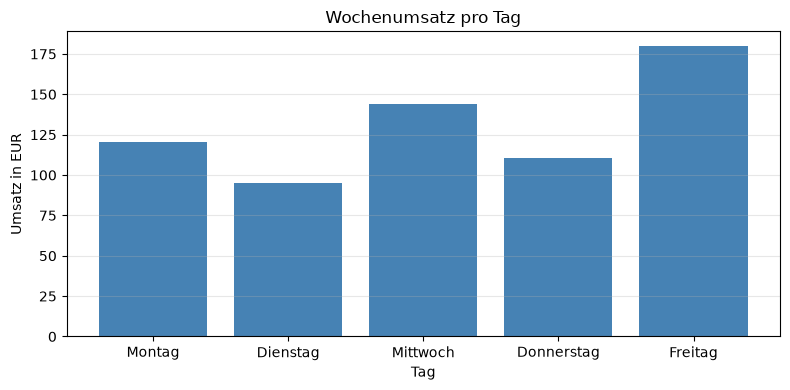

In [6]:
import matplotlib.pyplot as plt

tage = [eintrag["tag"] for eintrag in geladene_daten]
umsaetze = [eintrag["umsatz_euro"] for eintrag in geladene_daten]

plt.figure(figsize=(8, 4))
plt.bar(tage, umsaetze, color="steelblue")
plt.title("Wochenumsatz pro Tag")
plt.xlabel("Tag")
plt.ylabel("Umsatz in EUR")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Beispiel: Wetterdaten analysieren

Die folgenden Werte sind erfundene Beispieldaten für eine Woche, keine aktuelle Wettervorhersage. Wir betrachten Temperatur und Niederschlag. Neben dem Durchschnitt helfen Minimum, Maximum, Niederschlagssumme und Anzahl der Regentage, die Woche einzuordnen.

In [7]:
wetterdaten = [
    {"tag": "Mo", "temperatur": 16, "niederschlag": 0},
    {"tag": "Di", "temperatur": 18, "niederschlag": 2},
    {"tag": "Mi", "temperatur": 15, "niederschlag": 5},
    {"tag": "Do", "temperatur": 20, "niederschlag": 0},
    {"tag": "Fr", "temperatur": 22, "niederschlag": 0},
    {"tag": "Sa", "temperatur": 19, "niederschlag": 1},
    {"tag": "So", "temperatur": 17, "niederschlag": 3},
]

temperaturen = [tag["temperatur"] for tag in wetterdaten]
niederschlaege = [tag["niederschlag"] for tag in wetterdaten]
durchschnittstemperatur = sum(temperaturen) / len(temperaturen)
waermster_tag = max(wetterdaten, key=lambda tag: tag["temperatur"])
kaeltester_tag = min(wetterdaten, key=lambda tag: tag["temperatur"])
regentage = sum(menge > 0 for menge in niederschlaege)

print(f"Durchschnittstemperatur: {durchschnittstemperatur:.1f} °C")
print(
    f"Temperaturspanne: {kaeltester_tag['temperatur']} bis "
    f"{waermster_tag['temperatur']} °C"
 )
print(f"Niederschlag insgesamt: {sum(niederschlaege)} mm")
print(f"Regentage: {regentage} von {len(wetterdaten)}")

Durchschnittstemperatur: 18.1 °C
Temperaturspanne: 15 bis 22 °C
Niederschlag insgesamt: 11 mm
Regentage: 4 von 7


Im Diagramm bekommt die Temperatur eine Linie und der Niederschlag eigene Balken. Die getrennten Achsen machen beide Größen lesbar, ohne Celsius und Millimeter miteinander zu vermischen.

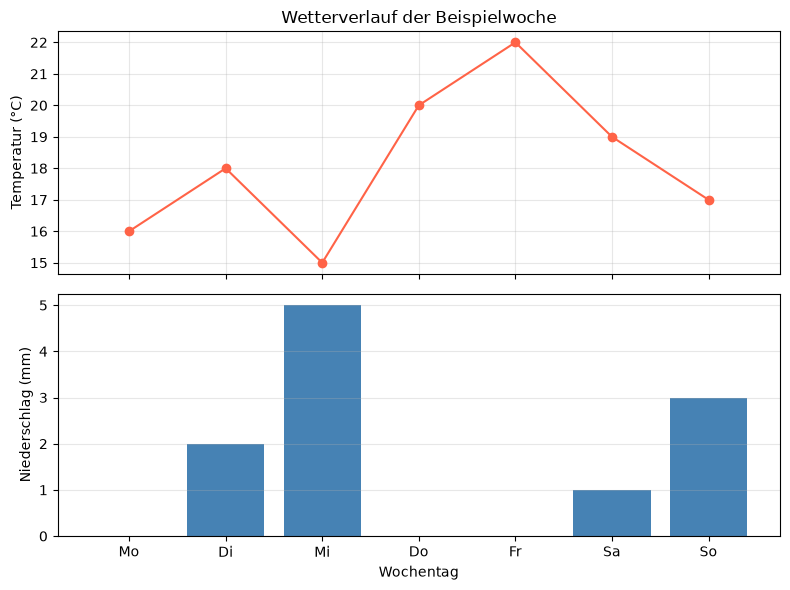

In [8]:
tage = [tag["tag"] for tag in wetterdaten]
fig, (ax_temp, ax_rain) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True
 )

ax_temp.plot(tage, temperaturen, marker="o", color="tomato")
ax_temp.set_title("Wetterverlauf der Beispielwoche")
ax_temp.set_ylabel("Temperatur (°C)")
ax_temp.grid(alpha=0.3)

ax_rain.bar(tage, niederschlaege, color="steelblue")
ax_rain.set_xlabel("Wochentag")
ax_rain.set_ylabel("Niederschlag (mm)")
ax_rain.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()